# Phân loại Spam/Ham bình luận sinh viên PTIT

**Thực nghiệm và ứng dụng — Nhóm Bảo, Cương, Phi, Phương**

Notebook trình bày quy trình xử lý văn bản, biểu diễn đặc trưng, huấn luyện và
đánh giá mô hình phân loại. Dữ liệu thực nghiệm sử dụng phiên bản `v7`.

Thực hiện các cell theo thứ tự trong môi trường Python 3.12 của project.


## 1. Cấu hình môi trường

Kiểm tra phiên bản thư viện, thiết lập đường dẫn dữ liệu và thư mục kết quả.
Seed được cố định để hỗ trợ tái lập thí nghiệm.


In [1]:
import os, sys
import importlib.metadata as metadata

assert sys.version_info[:2] == (3, 12), "Chọn kernel Python 3.12 trong .venv của project."
PACKAGES = {
    "numpy": "1.26.4", "scipy": "1.13.1", "pandas": "2.2.3",
    "scikit-learn": "1.6.1", "matplotlib": "3.10.3", "joblib": "1.5.1",
    "gensim": "4.4.0", "underthesea": "8.3.0", "jinja2": "3.1.6",
}
ENVIRONMENT = {name: metadata.version(name) for name in PACKAGES}
assert ENVIRONMENT == PACKAGES, "Cài requirements/notebook.txt bằng Python trong .venv rồi restart kernel."
print("Phiên bản thư viện khớp cấu hình thực nghiệm.")


Phiên bản thư viện khớp cấu hình thực nghiệm.


In [2]:
import os, sys
from pathlib import Path

# Xác định thư mục gốc để nạp các module của project.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "pipeline/__init__.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Mở notebook trong thư mục project có pipeline/ và external/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json, time, tempfile
import inspect
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from pipeline.presentation.notebook_display import display_readable as display
from joblib import Memory
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)

SEED = 42
np.random.seed(SEED)
N_JOBS = int(os.environ.get("SPAMHAM_N_JOBS", "2"))
ARTIFACT_DIR = Path(os.environ.get("SPAMHAM_OUTPUT_DIR", str(PROJECT_ROOT / "artifacts/spamham")))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = Path(os.environ.get("SPAMHAM_CSV", str(PROJECT_ROOT / "data/final/labeled_v7.csv")))
PROCESSED_PATH = PROJECT_ROOT / "data/processed/v7_preprocessed.csv"
pd.set_option("display.max_colwidth", 100)
print("Python:", sys.version.split()[0], "| jobs:", N_JOBS)
display(pd.Series(ENVIRONMENT, name="version").to_frame())


Python: 3.12.14 | jobs: 2


#,version
numpy,1.26.4
scipy,1.13.1
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.3
joblib,1.5.1
gensim,4.4.0
underthesea,8.3.0
jinja2,3.1.6


In [3]:
from pipeline.prepare import preprocess_for_model as preprocessing_module
from pipeline.features import spam_features as features_module
from pipeline.prepare.preprocess_for_model import preprocess, STOP_WORDS
from pipeline.modeling.training_utils import (norm_key, bucket, grouped_folds, undersampled_search,
                                              tune_svm_threshold, predict_record, sample_training_indices)
from pipeline.modeling.experiments import FEATURES, MODELS, make_pipe, fit_experiment, evaluate, boot_ci
from pipeline.inference.predict import predict_spam


## 2. Khảo sát dữ liệu

Đọc trực tiếp `data/final/labeled_v7.csv`. Hai nhãn gồm **ham** — bình luận thông
thường và **spam** — nội dung rác hoặc chào mời. Khảo sát số mẫu, phân bố nhãn,
độ dài và loại bình luận; kiểm tra ID, văn bản rỗng và các nội dung lặp.

Bảng trích 6 bình luận cho mỗi nhãn từ chính file dữ liệu, giữ ID để đối chiếu.
Các biểu đồ và thống kê được tính trên toàn bộ tập dữ liệu.


In [4]:
raw = pd.read_csv(CSV_PATH, keep_default_na=False, dtype={"id": str})
raw["label"] = raw["label"].str.strip().str.lower()
assert raw.id.is_unique and raw.id.str.strip().ne("").all(), "ID phải duy nhất và không rỗng."
assert set(raw.label) == {"ham", "spam"}, "Dữ liệu cần hai nhãn ham/spam."
assert raw.cleaned_text.str.strip().ne("").all(), "cleaned_text không được rỗng."

y_all = raw.label.eq("spam").astype(int).to_numpy()
exact_keys = raw.cleaned_text.str.normalize("NFC").str.lower().str.strip()
DATA_AUDIT = {
    "rows": len(raw), "labels": raw.label.value_counts().to_dict(),
    "duplicate_ids": int(raw.id.duplicated().sum()),
    "empty_cleaned_text": int(raw.cleaned_text.str.strip().eq("").sum()),
    "rows_in_repeated_text_groups": int(exact_keys.duplicated(keep=False).sum()),
    "text_groups_with_conflicting_labels": int((raw.groupby(exact_keys).label.nunique() > 1).sum()),
}
distribution = raw.label.value_counts().rename("Số bình luận").to_frame()
distribution["Tỷ lệ (%)"] = (distribution["Số bình luận"] / len(raw) * 100).round(2)
display(pd.Series(DATA_AUDIT, name="Thống kê").to_frame())
display(distribution)
preview_indices = raw.groupby("label").sample(n=6, random_state=SEED).index
display(raw.loc[preview_indices, ["id", "label", "text", "cleaned_text", "comment_type", "reaction_count"]])


#,Thống kê
rows,38233
labels,"{'ham': 32907, 'spam': 5326}"
duplicate_ids,0
empty_cleaned_text,0
rows_in_repeated_text_groups,2729
text_groups_with_conflicting_labels,27


label,Số bình luận,Tỷ lệ (%)
ham,32907,86.07
spam,5326,13.93


#,id,label,text,cleaned_text,comment_type,reaction_count
24256,cmt_25447,ham,Chắc đc. Hạn đến hết ngày 24/8 mà,Chắc đc. Hạn đến hết ngày 24 8 mà,comment,1
14203,cmt_14817,ham,Rõ ràng,Rõ ràng,comment,0
14358,cmt_14993,ham,Im luôn ạ,Im luôn ạ,comment,1
4799,cmt_4919,ham,Hieu Duc chịu,Hieu Duc chịu,reply,0
5020,cmt_5150,ham,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,reply,0
21683,cmt_22788,ham,"t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc","t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc",comment,1
20881,cmt_21963,spam,.,.,comment,0
35596,p2_cmt_3879,spam,Ph Tr Đức em vô nhóm c ghim đầu nhen,Ph Tr Đức em vô nhóm c ghim đầu nhen,reply,0
35835,p2_cmt_4175,spam,Trần Việt Đức e add và rep str c nhậnn nha,Trần Việt Đức e add và rep str c nhậnn nha,reply,0
21093,cmt_22180,spam,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee🤩,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee,comment,0


label,count,mean,std,min,25%,50%,75%,max
ham,32907.0,11.3,13.3,1.0,5.0,8.0,13.0,667.0
spam,5326.0,13.6,24.3,1.0,2.0,6.0,12.0,315.0


comment_type,ham,spam
comment,0.842,0.158
reply,0.89,0.11


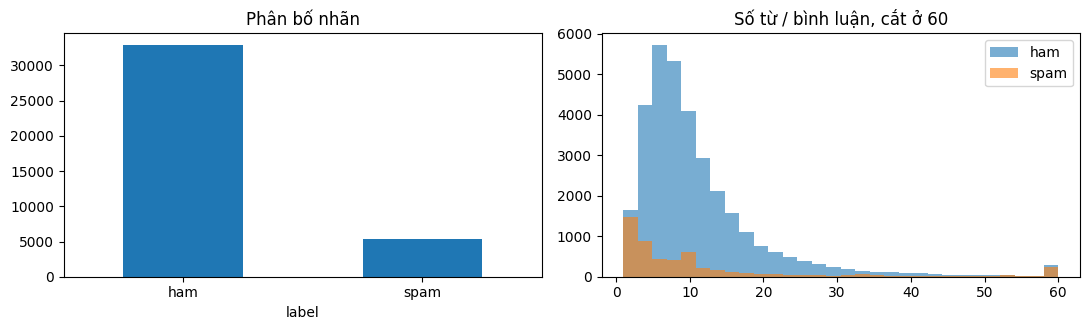

In [5]:
raw["n_words"] = raw["cleaned_text"].str.split().str.len()
display(raw.groupby("label")["n_words"].describe().round(1))
display(pd.crosstab(raw["comment_type"], raw["label"], normalize="index").round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
raw["label"].value_counts().plot.bar(ax=ax[0], rot=0, title="Phân bố nhãn")
for label in ["ham", "spam"]:
    ax[1].hist(raw.loc[raw.label == label, "n_words"].clip(upper=60), bins=30, alpha=.6, label=label)
ax[1].set_title("Số từ / bình luận, cắt ở 60"); ax[1].legend()
plt.tight_layout(); plt.show()


## 3. Tiền xử lý văn bản

Thực hiện trên toàn bộ bình luận trong v7. Giữ `text` gốc và `cleaned_text` có sẵn;
chuẩn hóa đầu vào mô hình, xử lý tên/URL/điện thoại/emoji, chuyển chữ thường và
tách từ tiếng Việt bằng underthesea. Các từ phủ định được giữ lại.

Tạo hai cột token tương ứng với cấu hình giữ và loại từ dừng. Lưu toàn bộ
kết quả vào `data/processed/v7_preprocessed.csv`, đọc lại và sử dụng các cột này
trong huấn luyện. Bảng trước/sau dùng cùng ID bình luận ở mục 2.
Cấu hình từ dừng được đối chiếu bằng cross-validation tại mục 5.


In [6]:
t0 = time.time()
prepared = raw[["id", "label", "text", "cleaned_text", "comment_type", "reaction_count"]].copy()
prepared["tokens_keep_stopwords"] = [preprocess(c, t, False) for c, t in zip(raw.cleaned_text, raw.text)]
prepared["tokens_remove_stopwords"] = prepared.tokens_keep_stopwords.map(
    lambda text: " ".join(token for token in text.split() if token not in STOP_WORDS))

PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
prepared.to_csv(PROCESSED_PATH, index=False, encoding="utf-8-sig")
prepared = pd.read_csv(PROCESSED_PATH, keep_default_na=False, dtype={"id": str})
assert prepared.id.tolist() == raw.id.tolist() and prepared.label.tolist() == raw.label.tolist()
TEXT = {"giữ stop words": prepared.tokens_keep_stopwords,
        "có loại stop words": prepared.tokens_remove_stopwords}

display(prepared.loc[preview_indices, ["id", "label", "text", "cleaned_text",
                                      "tokens_keep_stopwords", "tokens_remove_stopwords"]])
print(f"Đã xử lý và lưu {len(prepared):,} bình luận trong {time.time()-t0:.1f}s.")
print("File:", PROCESSED_PATH.relative_to(PROJECT_ROOT).as_posix())


#,id,label,text,cleaned_text,tokens_keep_stopwords,tokens_remove_stopwords
24256,cmt_25447,ham,Chắc đc. Hạn đến hết ngày 24/8 mà,Chắc đc. Hạn đến hết ngày 24 8 mà,chắc đc . hạn đến hết ngày 24 8 mà,chắc đc . hạn hết ngày 24 8
14203,cmt_14817,ham,Rõ ràng,Rõ ràng,rõ_ràng,rõ_ràng
14358,cmt_14993,ham,Im luôn ạ,Im luôn ạ,im luôn ạ,im
4799,cmt_4919,ham,Hieu Duc chịu,Hieu Duc chịu,hieu duc chịu,hieu duc chịu
5020,cmt_5150,ham,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,xuân nhật_a ơi thầy_hùng cho điểm thấp lắm ạ,xuân nhật_a thầy_hùng điểm thấp
21683,cmt_22788,ham,"t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc","t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc","t cũng như b nè về mang ra bí_thư khu_phố hoặc xã_phường ấy b , ngta đóng_dấu cho là đc","t b mang bí_thư khu_phố xã_phường b , ngta đóng_dấu đc"
20881,cmt_21963,spam,.,.,.,.
35596,p2_cmt_3879,spam,Ph Tr Đức em vô nhóm c ghim đầu nhen,Ph Tr Đức em vô nhóm c ghim đầu nhen,ph tr_đức em vô nhóm c ghim đầu nhen,ph tr_đức em vô nhóm c ghim đầu nhen
35835,p2_cmt_4175,spam,Trần Việt Đức e add và rep str c nhậnn nha,Trần Việt Đức e add và rep str c nhậnn nha,user_name e_add và rep str c nhậnn nha,user_name e_add rep str c nhậnn
21093,cmt_22180,spam,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee🤩,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee,còn câu_lạc_bộ sách và hành_động ptit mở đơn nốt hôm_nay nhee emoji_token,câu_lạc_bộ sách hành_động ptit mở đơn nốt hôm_nay nhee emoji_token


Đã xử lý và lưu 38,233 bình luận trong 20.9s.
File: data/processed/v7_preprocessed.csv


## 4. Thiết kế thực nghiệm

Chia dữ liệu theo nhóm văn bản chuẩn hóa thành **train** và **test**, tỷ lệ xấp xỉ
80/20. Các nội dung có cùng khóa được giữ trong cùng nhóm để hạn chế trùng lặp
giữa các tập. Cách chia này chưa loại trừ mọi nội dung gần trùng hoặc ngữ cảnh chung.

| Thành phần | Vai trò |
|---|---|
| Train | Phát triển mô hình, lựa chọn cấu hình và huấn luyện cuối. |
| Validation | Phần được giữ lại để chấm điểm trong một lượt cross-validation. |
| 5-fold cross-validation (CV) | Luân phiên dùng bốn fold train và một fold validation, thực hiện năm lượt. |
| Test | Đánh giá các cấu hình đã xác định; không dùng để chọn tham số hoặc ngưỡng. |

**CV F1** là trung bình F1 của lớp spam trên năm fold validation và là tiêu chí
lựa chọn cấu hình. CV Precision và CV Recall được tổng hợp trên cùng các fold.
Sau lựa chọn, mô hình được huấn luyện trên toàn bộ train trước khi dự đoán test.

Các chỉ số CV phục vụ phát triển và có thể lạc quan do tìm nhiều cấu hình;
đây không phải thiết kế nested CV. Test được dùng để báo cáo kết quả cuối.
Lấy mẫu chỉ thực hiện trong phần train của mỗi fold; ngưỡng lấy từ dự đoán
ngoài fold (OOF) của train. Validation và test giữ nguyên phân bố nhãn.


In [7]:
keys = raw["cleaned_text"].map(norm_key).to_numpy()
is_test = np.array([bucket(key, "test") == 0 for key in keys])
train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
y_train, y_test = y_all[train_idx], y_all[test_idx]
assert len(np.unique(y_train)) == len(np.unique(y_test)) == 2
assert not set(keys[train_idx]) & set(keys[test_idx])
CV_FOLDS = grouped_folds(keys[train_idx], y_train)

split_table = pd.DataFrame([
    {"Tập": name, "Số mẫu": len(labels), "Số mẫu spam": int(labels.sum()), "Tỷ lệ spam (%)": labels.mean() * 100}
    for name, labels in [("Train", y_train), ("Test", y_test)]
]).set_index("Tập")
display(split_table.round(2))
fold_table = pd.DataFrame([
    {"Fold": i + 1, "Số mẫu huấn luyện": len(tr), "Số mẫu validation": len(va),
     "Số mẫu spam trong validation": int(y_train[va].sum())}
    for i, (tr, va) in enumerate(CV_FOLDS)
]).set_index("Fold")
display(fold_table)
print("Mỗi dòng là một lượt CV; phần validation không được dùng để fit mô hình của lượt đó.")


Tập,Số mẫu,Số mẫu spam,Tỷ lệ spam (%)
Train,30759,4375,14.22
Test,7474,951,12.72


Fold,Số mẫu huấn luyện,Số mẫu validation,Số mẫu spam trong validation
1,24815,5944,764
2,24327,6432,1187
3,24554,6205,856
4,24529,6230,789
5,24811,5948,779


Mỗi dòng là một lượt CV; phần validation không được dùng để fit mô hình của lượt đó.


## 5. Xây dựng và huấn luyện mô hình

Ba phương pháp biểu diễn **BoW, TF-IDF, FastText** được kết hợp với hai họ mô hình
**Naive Bayes, SVM**, tạo thành sáu tổ hợp cơ sở. BoW/TF-IDF dùng MultinomialNB
hoặc LinearSVC. FastText dùng GaussianNB hoặc StandardScaler kết hợp LinearSVC;
GaussianNB cho phép đặc trưng có giá trị âm. FastText khai thác subword để biểu
diễn từ, kể cả một số từ chưa có trong từ vựng train.

Các tổ hợp cơ sở dùng toàn bộ phần train, không lấy mẫu lại; SVM không dùng
trọng số lớp, NB dùng ngưỡng 0,5 và SVM dùng ngưỡng điểm quyết định 0.
Từ vựng, IDF, embedding và scaler chỉ được học trong phần train của từng fold.
Siêu tham số được tìm bằng CV F1 spam.

Đối chiếu hai cấu hình từ dừng bằng CV, sau đó dùng cấu hình được chọn để so
sánh sáu tổ hợp và khảo sát chiến lược xử lý mất cân bằng. Bảng dưới chỉ dùng
điểm validation; chưa đánh giá test.


In [8]:
# Các phép fit và tìm tham số nằm trong pipeline/modeling/experiments.py.
cache_dir = tempfile.TemporaryDirectory(prefix="spamham_cache_", dir=ARTIFACT_DIR)
cache = Memory(cache_dir.name, verbose=0)
PREPROCESS_RESULTS = []
for pre in TEXT:
    X_train_text = TEXT[pre].iloc[train_idx].to_numpy()
    for feature in FEATURES:
        for algorithm in MODELS:
            record = fit_experiment(pre, feature, algorithm, X_train_text, y_train, CV_FOLDS,
                                    seed=SEED, cache=cache, n_jobs=N_JOBS)
            PREPROCESS_RESULTS.append(record)
    print("Hoàn tất CV:", pre, flush=True)

cv_comparison = pd.DataFrame(PREPROCESS_RESULTS).pivot(
    index=["Đặc trưng", "Thuật toán"], columns="Tiền xử lý", values="CV F1 (spam)")
cv_comparison = cv_comparison.rename(columns={"giữ stop words": "CV F1 — giữ từ dừng",
                                             "có loại stop words": "CV F1 — loại từ dừng"})
display(cv_comparison.round(4))
MAIN_PRE = max(PREPROCESS_RESULTS, key=lambda r: r["CV F1 (spam)"])["Tiền xử lý"]
RESULTS = [r for r in PREPROCESS_RESULTS if r["Tiền xử lý"] == MAIN_PRE]
for i, record in enumerate(RESULTS, 1):
    record["Mã"] = f"B{i}"
CV_COLS = ["CV Precision (spam)", "CV Recall (spam)", "CV F1 (spam)"]
display(pd.DataFrame(RESULTS)[["Mã", "Đặc trưng", "Thuật toán", *CV_COLS]].round(4))
display(pd.DataFrame(RESULTS)[["Mã", "Tham số"]])
focus = max(RESULTS, key=lambda r: r["CV F1 (spam)"])
assert (focus["Đặc trưng"], focus["Thuật toán"]) == ("TF-IDF", "SVM"), "Cần xem lại phạm vi khảo sát nếu ứng viên dẫn đầu thay đổi."
display(Markdown(f"**Cấu hình tiền xử lý:** {MAIN_PRE}. **Ứng viên dẫn đầu:** "
                 f"{focus['Mã']} — TF-IDF + SVM, CV F1 = {focus['CV F1 (spam)']:.4f}. "
                 "Các phần tiếp theo sử dụng cấu hình từ dừng này."))


Hoàn tất CV: giữ stop words


Hoàn tất CV: có loại stop words


#,CV F1 — loại từ dừng,CV F1 — giữ từ dừng
"('BoW', 'Naive Bayes')",0.5859,0.6077
"('BoW', 'SVM')",0.6306,0.7091
"('FastText', 'Naive Bayes')",0.4894,0.5594
"('FastText', 'SVM')",0.6653,0.6794
"('TF-IDF', 'Naive Bayes')",0.5835,0.5959
"('TF-IDF', 'SVM')",0.7562,0.7736


#,Mã,Đặc trưng,Thuật toán,CV Precision (spam),CV Recall (spam),CV F1 (spam)
0,B1,BoW,Naive Bayes,0.7582,0.5153,0.6077
1,B2,BoW,SVM,0.7295,0.6906,0.7091
2,B3,TF-IDF,Naive Bayes,0.8263,0.4723,0.5959
3,B4,TF-IDF,SVM,0.9001,0.6806,0.7736
4,B5,FastText,Naive Bayes,0.4971,0.641,0.5594
5,B6,FastText,SVM,0.8264,0.58,0.6794


#,Mã,Tham số
0,B1,"{'clf__alpha': 1.0, 'vec__ngram_range': (1, 2)}"
1,B2,"{'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}"
2,B3,"{'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}"
3,B4,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}"
4,B5,"{'clf__var_smoothing': 0.001, 'vec__pooling': 'tfidf'}"
5,B6,"{'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}"


**Cấu hình tiền xử lý:** giữ stop words. **Ứng viên dẫn đầu:** B4 — TF-IDF + SVM, CV F1 = 0.7736. Các phần tiếp theo sử dụng cấu hình từ dừng này.

### 5.1. Khảo sát các chiến lược xử lý mất cân bằng

TF-IDF + SVM dẫn đầu bước so sánh cơ sở theo CV F1. Giữ cố định biểu diễn và bộ
phân loại, đối chiếu ba chiến lược với cấu hình không điều chỉnh:

| Chiến lược | Dữ liệu train | Trọng số lớp | Ngưỡng điểm quyết định |
|---|---|---|---|
| Không điều chỉnh | Nguyên bản | Không | 0 |
| Trọng số balanced | Nguyên bản | Tính từ số mẫu mỗi lớp | 0 |
| Under-sampling 2:1 | Giữ spam, giảm ham | Không | 0 |
| Điều chỉnh ngưỡng | Nguyên bản | Không | Chọn bằng OOF trên train |

Balanced dùng trọng số `n_samples / (n_classes × n_samples_of_class)` trong
phần train đang fit. Under-sampling chọn ngẫu nhiên tối đa hai ham trên mỗi spam,
thực hiện riêng trong train của mỗi fold; tỷ lệ 2:1 là cấu hình khảo sát.

Nhánh ngưỡng giữ siêu tham số của SVM không điều chỉnh, tạo decision score OOF
bằng cách fit lại trên bốn fold và dự đoán fold còn lại. Khảo sát các ngưỡng từ
199 phân vị 1–99%, ngưỡng 0 và hai biên; chọn theo trung bình F1 validation.
Các chiến lược được thử riêng, không kết hợp với nhau. C và n-gram được tìm lại
cho balanced và under-sampling với cùng lưới cơ sở.

Thiết kế tập trung vào ứng viên dẫn đầu, chưa khảo sát mọi chiến lược trên cả
sáu tổ hợp. Kết luận lựa chọn chỉ giới hạn trong các cấu hình đã thực nghiệm.


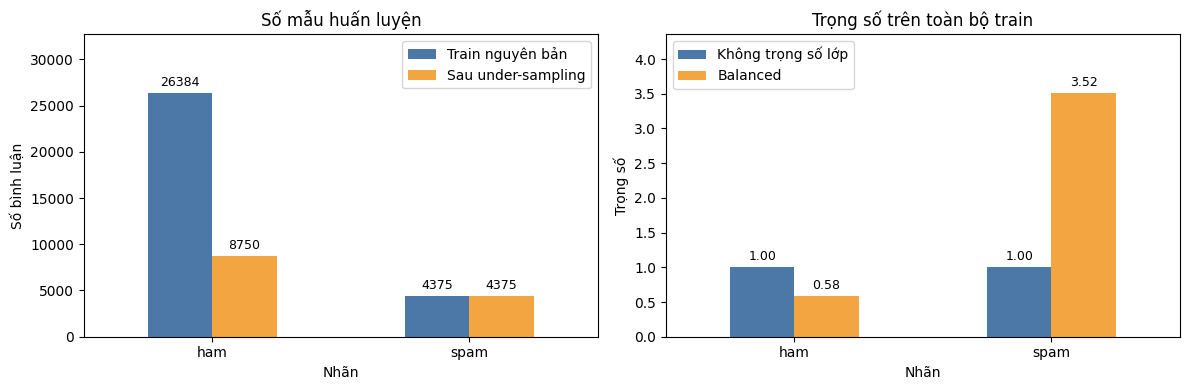

Mỗi fold tính lại trọng số và lấy mẫu từ phần train của fold; validation/test giữ nguyên.


In [9]:
sampled_indices = sample_training_indices(y_train, np.arange(len(y_train)), seed=SEED, ratio=2)
before_counts = pd.Series(np.where(y_train == 1, "spam", "ham")).value_counts().reindex(["ham", "spam"])
after_counts = pd.Series(np.where(y_train[sampled_indices] == 1, "spam", "ham")).value_counts().reindex(["ham", "spam"])
sampling_table = pd.DataFrame({"Train nguyên bản": before_counts, "Sau under-sampling": after_counts})
weights = len(y_train) / (2 * before_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sampling_table.plot.bar(ax=axes[0], rot=0, color=["#4c78a8", "#f2a541"])
axes[0].set(title="Số mẫu huấn luyện", ylabel="Số bình luận", xlabel="Nhãn")
weight_table = pd.DataFrame({"Không trọng số lớp": [1.0, 1.0], "Balanced": weights}, index=["ham", "spam"])
weight_table.plot.bar(ax=axes[1], rot=0, color=["#4c78a8", "#f2a541"])
axes[1].set(title="Trọng số trên toàn bộ train", ylabel="Trọng số", xlabel="Nhãn")
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f" if ax is axes[1] else "%.0f", padding=3, fontsize=9)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.18)
plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "imbalance_training.png", dpi=140, bbox_inches="tight")
plt.show()
print("Mỗi fold tính lại trọng số và lấy mẫu từ phần train của fold; validation/test giữ nguyên.")


In [10]:
X_tr_text = TEXT[MAIN_PRE].iloc[train_idx].to_numpy()
balanced = fit_experiment(MAIN_PRE, "TF-IDF", "SVM", X_tr_text, y_train, CV_FOLDS,
                          seed=SEED, cache=cache, n_jobs=N_JOBS,
                          class_weight="balanced", strategy="Trọng số balanced")
balanced["Mã"] = "S1"

pipe, grid, _ = make_pipe("TF-IDF", "SVM", seed=SEED, cache=cache, n_jobs=N_JOBS)
start = time.time()
us_model, us_metrics, us_params, us_count = undersampled_search(pipe, grid, X_tr_text, y_train, CV_FOLDS, SEED)
under = {"Mã": "S2", "Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "SVM",
         "Chiến lược": "Under-sampling 2:1", **us_metrics, "Tham số": us_params,
         "Thời gian (s)": time.time() - start, "_model": us_model, "_threshold": 0.0}
assert us_count == len(sampled_indices)

start = time.time()
threshold_model, threshold_metrics, threshold = tune_svm_threshold(focus["_model"], X_tr_text, y_train, CV_FOLDS)
tuned = {"Mã": "S3", "Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "SVM",
         "Chiến lược": "Điều chỉnh ngưỡng", **threshold_metrics,
         "Tham số": {**focus["Tham số"], "threshold": threshold},
         "Thời gian (s)": time.time() - start, "_model": threshold_model, "_threshold": threshold}
SUPPLEMENTARY = [balanced, under, tuned]
STRATEGIES = [focus, *SUPPLEMENTARY]
CANDIDATES = RESULTS + SUPPLEMENTARY
best = max(CANDIDATES, key=lambda r: r["CV F1 (spam)"])

strategy_cv = pd.DataFrame([
    {"Mã": r["Mã"], "Chiến lược": r["Chiến lược"], "Số mẫu train": us_count if r is under else len(y_train),
     "Ngưỡng SVM": r["_threshold"], **{k: r[k] for k in CV_COLS}} for r in STRATEGIES
])
display(strategy_cv.round(4))
display(pd.DataFrame(STRATEGIES)[["Mã", "Tham số"]])
strategy_cv.to_csv(ARTIFACT_DIR / "imbalance_cv.csv", index=False, encoding="utf-8-sig")
SELECTED_NAME = f"{best['Mã']} — {best['Đặc trưng']} + {best['Thuật toán']} — {best['Chiến lược']}"
display(Markdown(f"**Lựa chọn theo CV:** {SELECTED_NAME}. "
                 f"CV F1 spam = {best['CV F1 (spam)']:.4f}; ngưỡng = {best['_threshold']:.4f}. "
                 "Lựa chọn này được xác định trước phần đánh giá test."))


#,Mã,Chiến lược,Số mẫu train,Ngưỡng SVM,CV Precision (spam),CV Recall (spam),CV F1 (spam)
0,B4,Không điều chỉnh,30759,0.0,0.9001,0.6806,0.7736
1,S1,Trọng số balanced,30759,0.0,0.7233,0.7964,0.758
2,S2,Under-sampling 2:1,13125,0.0,0.8038,0.7276,0.7629
3,S3,Điều chỉnh ngưỡng,30759,-0.1776,0.849,0.7353,0.7876


#,Mã,Tham số
0,B4,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}"
1,S1,"{'clf__C': 0.1, 'clf__class_weight': 'balanced', 'vec__ngram_range': (1, 2)}"
2,S2,"{'clf__C': 0.1, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}"
3,S3,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2), 'threshold': -0.17762792522140153}"


**Lựa chọn theo CV:** S3 — TF-IDF + SVM — Điều chỉnh ngưỡng. CV F1 spam = 0.7876; ngưỡng = -0.1776. Lựa chọn này được xác định trước phần đánh giá test.

### 5.2. Mô hình hiện đại

Phần triển khai mô hình hiện đại và so sánh với các mô hình cơ sở sẽ được bổ sung.


In [11]:
# Phần triển khai mô hình hiện đại sẽ được bổ sung tại đây.


## 6. Đánh giá mô hình

Báo cáo Accuracy, Precision, Recall, F1 của lớp spam và Average Precision (AP)
trên cùng tập test. Sáu tổ hợp cơ sở dùng cấu hình từ dừng đã chọn, train nguyên
bản và ngưỡng mặc định; SVM không dùng trọng số lớp. Các chiến lược TF-IDF + SVM
được đối chiếu riêng ở mục 6.1. Không dùng chỉ số test để chọn lại cấu hình.


In [12]:
for record in CANDIDATES:
    evaluate(record, TEXT[record["Tiền xử lý"]].iloc[test_idx].to_numpy(), y_test)
METRICS = ["Accuracy", "Precision", "Recall", "F1", "AP"]
REPORT_COLS = ["Mã", "Tiền xử lý", "Đặc trưng", "Thuật toán", "Chiến lược", *CV_COLS,
               *METRICS, "Tham số", "Thời gian (s)"]
metrics = pd.DataFrame([{k: r[k] for k in REPORT_COLS} | {"Ngưỡng": r["_threshold"]} for r in CANDIDATES])
sel = RESULTS
display(metrics.iloc[:len(RESULTS)][["Mã", "Đặc trưng", "Thuật toán", *METRICS]].round(4))
baseline = pd.DataFrame([{"Cấu hình": "Luôn dự đoán ham", "Accuracy": 1 - y_test.mean(),
                          "Precision": 0.0, "Recall": 0.0, "F1": 0.0}])
display(baseline.round(4))
display(Markdown(f"**Cấu hình được chọn bằng CV:** {SELECTED_NAME}. "
                 f"Test Precision = {best['Precision']:.4f}, Recall = {best['Recall']:.4f}, "
                 f"F1 = {best['F1']:.4f}."))


#,Mã,Đặc trưng,Thuật toán,Accuracy,Precision,Recall,F1,AP
0,B1,BoW,Naive Bayes,0.9141,0.7441,0.4953,0.5947,0.732
1,B2,BoW,SVM,0.9241,0.711,0.6803,0.6953,0.7492
2,B3,TF-IDF,Naive Bayes,0.9257,0.8402,0.5142,0.638,0.7988
3,B4,TF-IDF,SVM,0.9419,0.8818,0.6278,0.7334,0.8117
4,B5,FastText,Naive Bayes,0.8493,0.4374,0.6425,0.5204,0.536
5,B6,FastText,SVM,0.9253,0.8259,0.5237,0.6409,0.7179


#,Cấu hình,Accuracy,Precision,Recall,F1
0,Luôn dự đoán ham,0.8728,0.0,0.0,0.0


**Cấu hình được chọn bằng CV:** S3 — TF-IDF + SVM — Điều chỉnh ngưỡng. Test Precision = 0.8374, Recall = 0.6877, F1 = 0.7552.

### 6.1. Ảnh hưởng của các chiến lược xử lý mất cân bằng

Đối chiếu bốn cấu hình **cùng TF-IDF + SVM** trên tập test. Cấu hình không điều
chỉnh là đối chứng và cũng là một dòng trong sáu tổ hợp ở trên; không phải mô hình
mới. Mục 5.1 dùng điểm CV để lựa chọn, còn mục này dùng test để đánh giá tác động.

**FP** là ham bị nhận nhầm thành spam; **FN** là spam bị bỏ sót. Đọc F1 cùng
Precision, Recall và số lỗi để nhận xét đánh đổi, thay vì chỉ nhìn Accuracy.


#,Mã,Chiến lược,Accuracy,Precision,Recall,F1,AP,FP,FN
0,B4,Không điều chỉnh,0.9419,0.8818,0.6278,0.7334,0.8117,80,354
1,S1,Trọng số balanced,0.9322,0.7139,0.7792,0.7451,0.8127,297,210
2,S2,Under-sampling 2:1,0.9394,0.7791,0.7308,0.7542,0.7826,197,256
3,S3,Điều chỉnh ngưỡng,0.9433,0.8374,0.6877,0.7552,0.8117,127,297


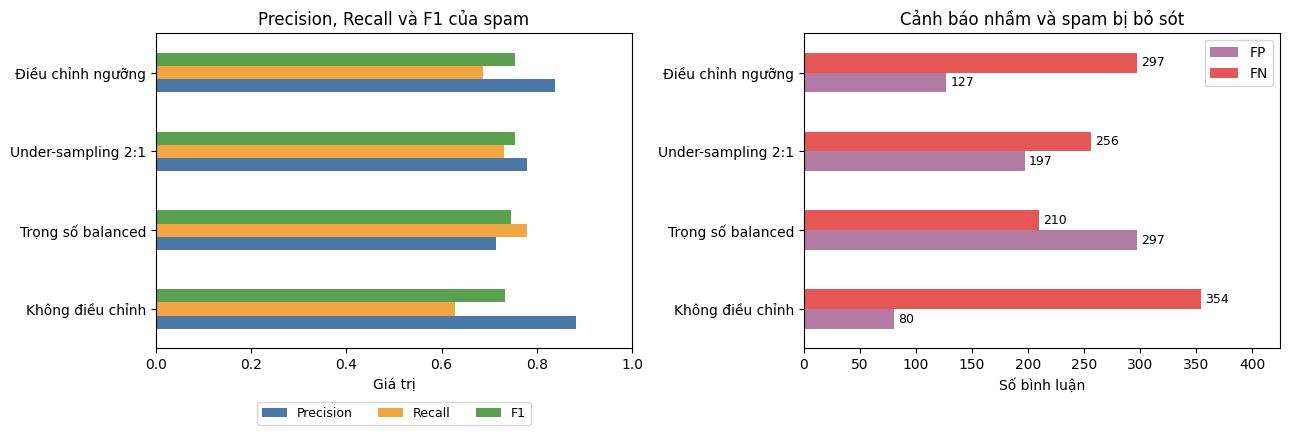

In [13]:
balance_rows = []
for record in STRATEGIES:
    tn, fp, fn, tp = confusion_matrix(y_test, record["_pred"], labels=[0, 1]).ravel()
    balance_rows.append({"Mã": record["Mã"], "Chiến lược": record["Chiến lược"],
                         **{k: record[k] for k in METRICS}, "FP": int(fp), "FN": int(fn)})
imbalance_report = pd.DataFrame(balance_rows)
display(imbalance_report.round(4))
imbalance_report.to_csv(ARTIFACT_DIR / "imbalance_comparison.csv", index=False, encoding="utf-8-sig")
plot_report = imbalance_report.set_index("Chiến lược")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_report[["Precision", "Recall", "F1"]].plot.barh(ax=axes[0], color=["#4c78a8", "#f2a541", "#59a14f"])
axes[0].set(title="Precision, Recall và F1 của spam", xlabel="Giá trị", ylabel="", xlim=(0, 1))
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
plot_report[["FP", "FN"]].plot.barh(ax=axes[1], color=["#b279a2", "#e45756"])
axes[1].set(title="Cảnh báo nhầm và spam bị bỏ sót", xlabel="Số bình luận", ylabel="")
for container in axes[1].containers:
    axes[1].bar_label(container, padding=3, fontsize=9)
axes[1].set_xlim(right=plot_report[["FP", "FN"]].to_numpy().max() * 1.2)
plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "imbalance_results.png", dpi=140, bbox_inches="tight")
plt.show()


### 6.2. Ma trận nhầm lẫn

Hàng thể hiện nhãn thực tế, cột thể hiện nhãn dự đoán. Hình thứ nhất đối chiếu
sáu tổ hợp cơ sở; hình thứ hai đối chiếu bốn chiến lược của TF-IDF + SVM.
Mỗi ô ghi số mẫu và tỷ lệ theo hàng để thấy rõ loại lỗi trong từng lớp.


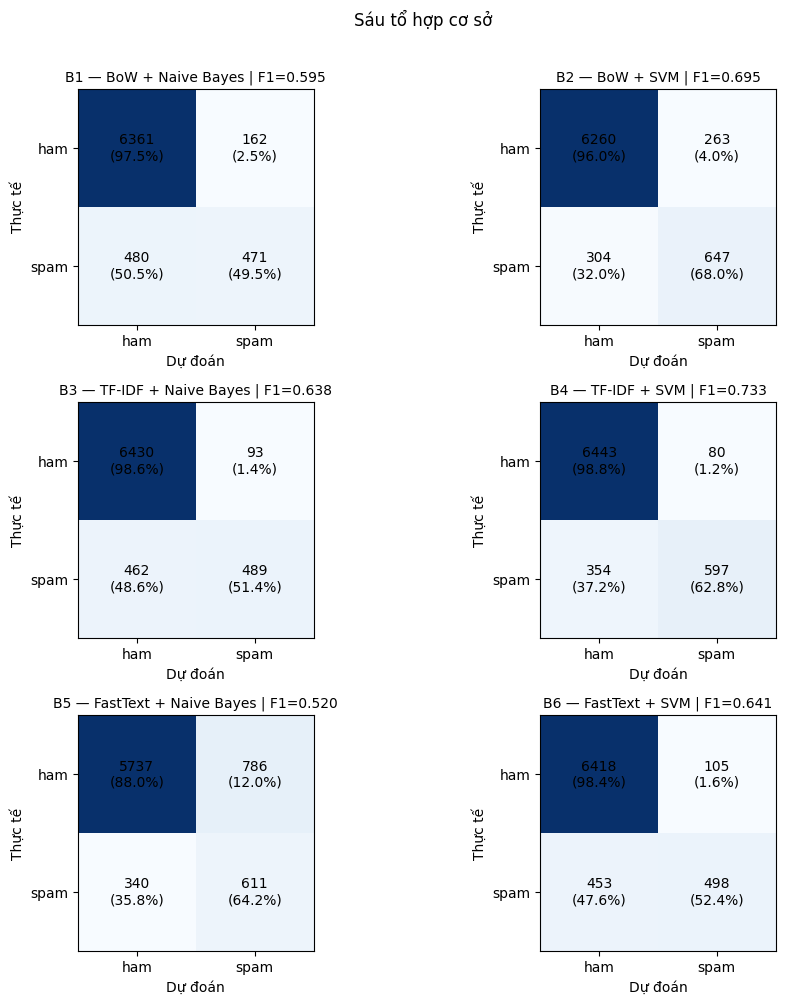

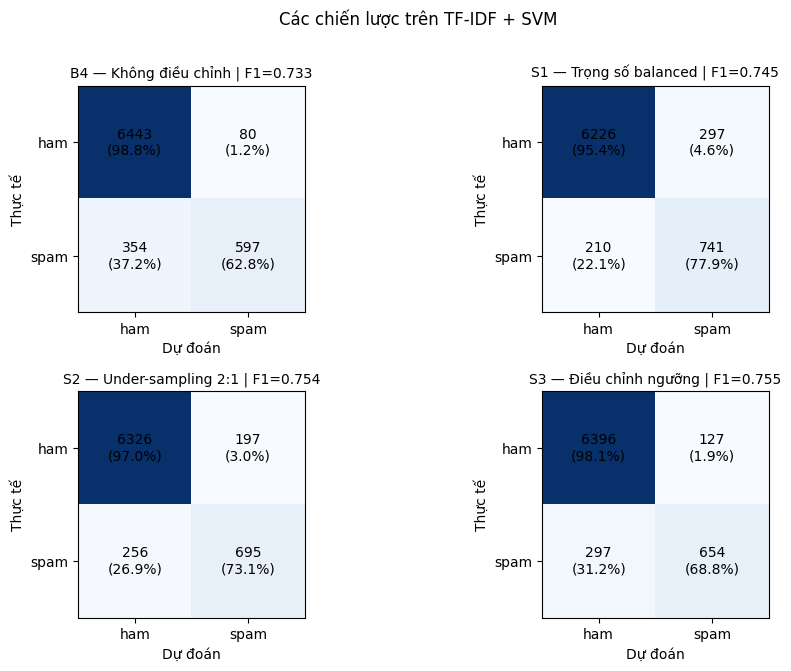

Ma trận của cấu hình được chọn: S3 — TF-IDF + SVM — Điều chỉnh ngưỡng


#,Dự đoán ham,Dự đoán spam
Thực tế ham,6396,127
Thực tế spam,297,654


In [14]:
def plot_confusions(records, nrows, ncols, title, filename):
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3.4 * nrows), squeeze=False)
    for ax, record in zip(axes.ravel(), records):
        matrix = confusion_matrix(y_test, record["_pred"], labels=[0, 1])
        ax.imshow(matrix, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{matrix[i,j]}\n({matrix[i,j]/matrix[i].sum():.1%})", ha="center", va="center")
        ax.set_xticks([0, 1], ["ham", "spam"])
        ax.set_yticks([0, 1], ["ham", "spam"])
        ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
        name = f"{record['Đặc trưng']} + {record['Thuật toán']}" if records is RESULTS else record["Chiến lược"]
        ax.set_title(f"{record['Mã']} — {name} | F1={record['F1']:.3f}", fontsize=10)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(ARTIFACT_DIR / filename, dpi=140, bbox_inches="tight")
    plt.show()

plot_confusions(RESULTS, 3, 2, "Sáu tổ hợp cơ sở", "confusion_baselines.png")
plot_confusions(STRATEGIES, 2, 2, "Các chiến lược trên TF-IDF + SVM", "confusion_strategies.png")
print("Ma trận của cấu hình được chọn:", SELECTED_NAME)
display(pd.DataFrame(confusion_matrix(y_test, best["_pred"], labels=[0, 1]),
                     index=["Thực tế ham", "Thực tế spam"], columns=["Dự đoán ham", "Dự đoán spam"]))


### 6.3. Đường Precision–Recall và khoảng tin cậy F1

Hình thứ nhất đối chiếu sáu tổ hợp cơ sở. Hình thứ hai tập trung vào các chiến
lược TF-IDF + SVM. Nhánh chỉ điều chỉnh ngưỡng có cùng mô hình và thứ tự decision
score với cấu hình không điều chỉnh, nên dùng chung đường PR và AP; hai điểm
đánh dấu thể hiện Precision/Recall tại ngưỡng 0 và ngưỡng được lựa chọn.

Bootstrap 500 lần theo dòng mô tả biến động F1 trên tập test cố định, gồm các
cấu hình cơ sở và chiến lược bổ sung. Khoảng tin cậy có giới hạn do phụ thuộc
giữa bình luận; không sử dụng để điều chỉnh lại mô hình.


#,Mã,Đặc trưng,Thuật toán,Chiến lược,F1,CI thấp,CI cao
0,B1,BoW,Naive Bayes,Không điều chỉnh,0.5947,0.5629,0.6227
1,B2,BoW,SVM,Không điều chỉnh,0.6953,0.6724,0.7193
2,B3,TF-IDF,Naive Bayes,Không điều chỉnh,0.638,0.6089,0.6655
3,B4,TF-IDF,SVM,Không điều chỉnh,0.7334,0.7106,0.7562
4,B5,FastText,Naive Bayes,Không điều chỉnh,0.5204,0.4969,0.5434
5,B6,FastText,SVM,Không điều chỉnh,0.6409,0.6148,0.6663
6,S1,TF-IDF,SVM,Trọng số balanced,0.7451,0.7243,0.7647
7,S2,TF-IDF,SVM,Under-sampling 2:1,0.7542,0.7325,0.7758
8,S3,TF-IDF,SVM,Điều chỉnh ngưỡng,0.7552,0.7337,0.7776


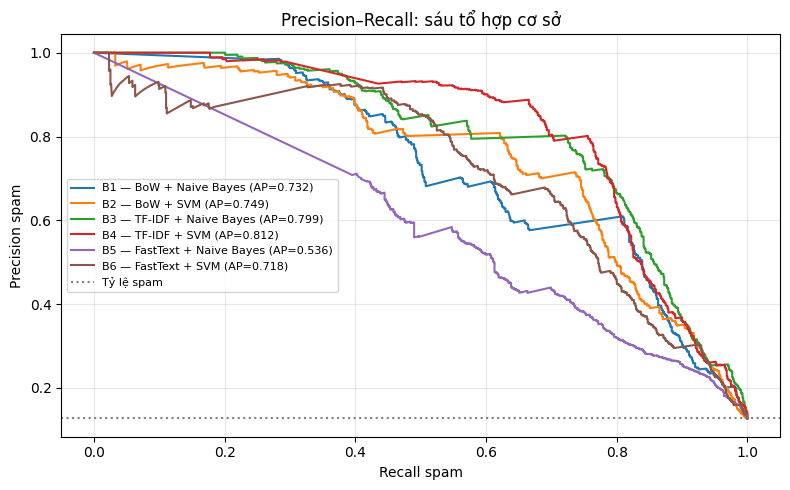

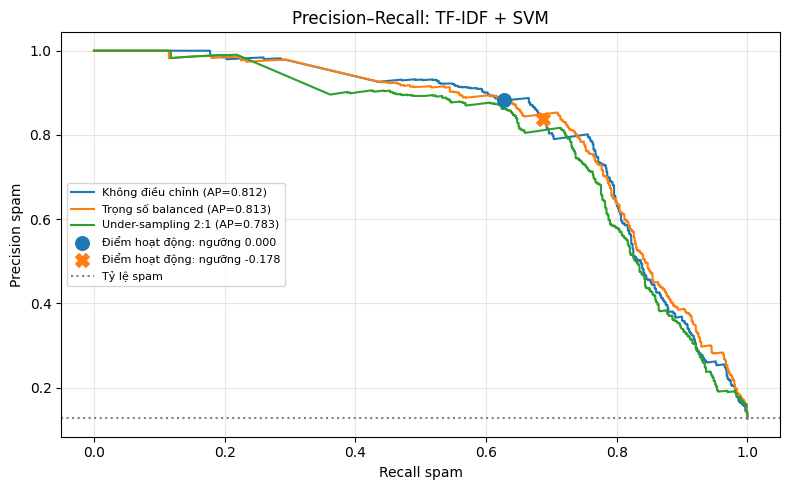

In [15]:
ci = []
for record in CANDIDATES:
    lo, hi = boot_ci(y_test, record["_pred"])
    ci.append({"Mã": record["Mã"], "Đặc trưng": record["Đặc trưng"], "Thuật toán": record["Thuật toán"],
               "Chiến lược": record["Chiến lược"], "F1": record["F1"], "CI thấp": lo, "CI cao": hi})
display(pd.DataFrame(ci).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for record in RESULTS:
    precision, recall, _ = precision_recall_curve(y_test, record["_score"])
    ax.plot(recall, precision, label=f"{record['Mã']} — {record['Đặc trưng']} + {record['Thuật toán']} (AP={record['AP']:.3f})")
ax.axhline(y_test.mean(), ls=":", color="gray", label="Tỷ lệ spam")
ax.set(xlabel="Recall spam", ylabel="Precision spam", title="Precision–Recall: sáu tổ hợp cơ sở")
ax.legend(fontsize=8); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "pr_baselines.png", dpi=140, bbox_inches="tight")
plt.show()

assert np.allclose(focus["_score"], tuned["_score"]), "Nhánh ngưỡng phải giữ nguyên decision score của mô hình đối chứng."
fig, ax = plt.subplots(figsize=(8, 5))
for record in [focus, balanced, under]:
    precision, recall, _ = precision_recall_curve(y_test, record["_score"])
    ax.plot(recall, precision, label=f"{record['Chiến lược']} (AP={record['AP']:.3f})")
for record, marker in [(focus, "o"), (tuned, "X")]:
    ax.scatter(record["Recall"], record["Precision"], marker=marker, s=95, zorder=5,
               label=f"Điểm hoạt động: ngưỡng {record['_threshold']:.3f}")
ax.axhline(y_test.mean(), ls=":", color="gray", label="Tỷ lệ spam")
ax.set(xlabel="Recall spam", ylabel="Precision spam", title="Precision–Recall: TF-IDF + SVM")
ax.legend(fontsize=8); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "pr_strategies.png", dpi=140, bbox_inches="tight")
plt.show()


## 7. Phân tích kết quả

Khảo sát đặc trưng và các trường hợp dự đoán sai của **cấu hình được chọn bằng CV**.
Với SVM, hệ số dương nghiêng về spam, hệ số âm nghiêng về ham; khi đổi ngưỡng,
ranh giới quyết định thay đổi nhưng hệ số đặc trưng được giữ nguyên.

Bảng FP/FN giữ ID, bình luận gốc, văn bản xử lý, nhãn thực tế, nhãn dự đoán và
điểm mô hình. Decision score của SVM không phải xác suất; so sánh với ngưỡng
được chọn để xác định nhãn. Ví dụ lỗi phục vụ phân tích, không tự sửa nhãn dữ liệu.


In [16]:
display(Markdown(f"**Cấu hình phân tích:** {SELECTED_NAME}; ngưỡng = {best['_threshold']:.4f}."))
selected_model = best["_model"]
if best["Đặc trưng"] in ("BoW", "TF-IDF"):
    vec, clf = selected_model.named_steps["vec"], selected_model.named_steps["clf"]
    names = vec.get_feature_names_out()
    importance = clf.coef_.ravel() if best["Thuật toán"] == "SVM" else clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    order = np.argsort(importance)
    display(pd.DataFrame({"Nghiêng về spam": names[order[::-1][:15]], "Nghiêng về ham": names[order[:15]]}))
errors = raw.iloc[test_idx][["id", "text"]].reset_index(drop=True).copy()
errors["Văn bản xử lý"] = TEXT[best["Tiền xử lý"]].iloc[test_idx].to_numpy()
errors["Thực tế"] = np.where(y_test == 1, "spam", "ham")
errors["Dự đoán"] = np.where(best["_pred"] == 1, "spam", "ham")
errors["Điểm mô hình"] = best["_score"]
print("Ham bị nhận nhầm thành spam (FP):")
display(errors[(errors["Thực tế"] == "ham") & (errors["Dự đoán"] == "spam")].sort_values("Điểm mô hình", ascending=False).head(8))
print("Spam bị bỏ sót (FN):")
display(errors[(errors["Thực tế"] == "spam") & (errors["Dự đoán"] == "ham")].sort_values("Điểm mô hình").head(8))


**Cấu hình phân tích:** S3 — TF-IDF + SVM — Điều chỉnh ngưỡng; ngưỡng = -0.1776.

#,Nghiêng về spam,Nghiêng về ham
0,urltoken,à
1,phonetoken,thôi
2,.,: )
3,ib chị,: (
4,nhắn_c,là
5,user_name,cảm_ơn
6,chiến_lê,quá
7,…,kìa
8,nguyễn_hữu_trọng,cũng
9,aptis,phải


Ham bị nhận nhầm thành spam (FP):


#,id,text,Văn bản xử lý,Thực tế,Dự đoán,Điểm mô hình
1720,cmt_9019,Đỗ Văn An poor 🙁,user_name poor emoji_token,ham,spam,1.0101477983829592
5260,cmt_28205,Nguyễn Thành Vinh 🙂điên k,user_name điên_k emoji_token,ham,spam,1.0101477983829592
3666,cmt_19384,DecisiveOwl9069 0388120543 b ib số này nha,user_name phonetoken b ib số này nha,ham,spam,0.9686141485207367
4686,cmt_25167,🌐 Chuyên ngành Thương mại Điện tử: D26CQTM01-B : https://m.me/j/AbY2lWGe8_9tO6hS/ D26CQTM02-B : https://m.me/j/AbZOYYseyk-laqbU/ D26CQTM03-B : https://m.me/j/AbYGu62eciZFmbYF/,chuyên_ngành thương_mại_điện_tử : d26cqtm01-b : urltoken d26cqtm02-b : urltoken d26cqtm03-b : urltoken emoji_token,ham,spam,0.9538239786248852
7233,p2_cmt_5708,Em nhắn c gửi nhne,em nhắn_c gửi nhne,ham,spam,0.8033513279219766
4941,cmt_26461,Em ib page hoặc nhắn c nha,em ib page hoặc nhắn_c nha,ham,spam,0.7138952076260332
2927,cmt_15359,Đạo Hứa,user_name,ham,spam,0.6889058040182241
6624,p2_cmt_2085,Lê Đức Công Toàn nện,user_name nện,ham,spam,0.6889058040182241


Spam bị bỏ sót (FN):


#,id,text,Văn bản xử lý,Thực tế,Dự đoán,Điểm mô hình
4474,cmt_23908,"Mạn đó thì nhiều lắm b, qtrong b có tìm ra ttam uy tín được hay k thôi, g ttam mọc lên như gì ấy mà, cần t rcm cho mấy ttam mà tham khảo thì nhắn t nhé","mạn đó thì nhiều lắm b , qtrong b có tìm ra ttam uy_tín được hay k thôi , g ttam mọc lên như gì ấy mà , cần t rcm cho mấy ttam mà tham_khảo thì nhắn_t nhé",spam,ham,-1.3485047965054866
5573,cmt_29814,Chi Yen có ạ,chi yen có ạ,spam,ham,-1.333541346375513
1770,cmt_9308,Lê Đình Phát toàn đi cắm r,user_name toàn đi cắm r,spam,ham,-1.3288763603909697
3010,cmt_15770,Em xin vs a ơi,em xin vs a ơi,spam,ham,-1.2619072960920283
6712,p2_cmt_2552,36k thì lấy,36 k thì lấy,spam,ham,-1.2561829517066807
5234,cmt_28081,Đăng Dươngg ib bạn này ạ hqua bạn em làm rơi,đăng dươngg ib bạn này ạ hqua bạn em làm rơi,spam,ham,-1.2501957902789362
3807,cmt_20233,Nhat Anh,nhat anh,spam,ham,-1.2428843608717424
743,cmt_3877,Martial The Tks b nh,martial the tks b nh,spam,ham,-1.2320128484809003


## 8. Lưu mô hình và dự đoán bình luận mới

Lưu **cấu hình được chọn bằng CV** tại `artifacts/spamham/spam_ham_ml_only.joblib`.
Bundle chứa pipeline đặc trưng–mô hình đã huấn luyện, ngưỡng quyết định và cấu
hình tiền xử lý. Các ứng viên còn lại được lưu dưới dạng bảng chỉ số để đối chiếu.

Nạp lại bundle, kiểm tra dự đoán trên test khớp với kết quả trước khi lưu, sau
đó áp dụng cho bình luận mới qua cùng bước tiền xử lý. Với SVM, score là điểm
quyết định; với NB, score là xác suất spam. Các câu demo minh họa cách sử dụng,
không thay thế đánh giá trên test và không bảo đảm mọi dự đoán đều đúng.

Đánh giá dùng văn bản đã chuẩn hóa trong dataset, còn demo nhận bình luận gốc.
Kiểm tra toàn bộ test cho thấy nhãn hai đường vào khớp nhau; một số score có thể
khác do nội dung `text` và `cleaned_text` sẵn có không hoàn toàn tương đương.


In [17]:
manifest = {"dataset_file": str(CSV_PATH), "processed_file": str(PROCESSED_PATH), "audit": DATA_AUDIT,
    "train_rows": len(train_idx), "test_rows": len(test_idx), "test_spam": int(y_test.sum()),
    "seed": SEED, "environment": ENVIRONMENT, "python": sys.version.split()[0],
    "completed_utc": datetime.now(timezone.utc).isoformat(), "modern_model": "not_implemented",
    "selection_rule": "max mean validation F1 on train CV; test not used for selection",
    "baseline_configurations": len(RESULTS), "additional_strategies": len(SUPPLEMENTARY),
    "selected": {k: best[k] for k in ["Mã", "Tiền xử lý", "Đặc trưng", "Thuật toán", "Chiến lược", *CV_COLS, *METRICS, "Tham số"]},
    "decision_threshold": best["_threshold"]}
bundle = {"model": best["_model"], "threshold": best["_threshold"],
    "remove_stop": best["Tiền xử lý"] == "có loại stop words", "manifest": manifest,
    "preprocessing_source": inspect.getsource(preprocessing_module),
    "features_source": inspect.getsource(features_module)}
for record in PREPROCESS_RESULTS + SUPPLEMENTARY:
    record["_model"].memory = None
model_path = ARTIFACT_DIR / "spam_ham_ml_only.joblib"
joblib.dump(bundle, model_path)
loaded = joblib.load(model_path)
X_verify = TEXT[best["Tiền xử lý"]].iloc[test_idx].to_numpy()
reloaded_pred, _ = predict_record({"_model": loaded["model"], "_threshold": loaded["threshold"]}, X_verify)
assert np.array_equal(reloaded_pred, best["_pred"])
raw_predictions = predict_spam(raw.iloc[test_idx].text.tolist(), loaded)
assert np.array_equal(raw_predictions.du_doan.eq("spam").astype(int).to_numpy(), best["_pred"])

display(Markdown(f"**Mô hình lưu và demo:** {SELECTED_NAME}; ngưỡng = {loaded['threshold']:.4f}."))
display(predict_spam(["Cho mình hỏi lịch thi với ạ", "Liên hệ 0901234567 hoặc https://example.com", "Nguyễn Văn An", "."], loaded))
metrics.to_csv(ARTIFACT_DIR / "metrics.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(ci).to_csv(ARTIFACT_DIR / "bootstrap_ci.csv", index=False)
(ARTIFACT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
cv_comparison.to_csv(ARTIFACT_DIR / "stopword_cv.csv", encoding="utf-8-sig")
errors.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
cache_dir.cleanup()
print("Đã lưu:", model_path.relative_to(PROJECT_ROOT).as_posix())
print("Dự đoán sau khi nạp lại và từ bình luận gốc khớp trên toàn bộ", len(test_idx), "mẫu test.")


**Mô hình lưu và demo:** S3 — TF-IDF + SVM — Điều chỉnh ngưỡng; ngưỡng = -0.1776.

#,text,score,score_type,du_doan
0,Cho mình hỏi lịch thi với ạ,-1.2542561405255837,decision_score,ham
1,Liên hệ 0901234567 hoặc https://example.com,2.968799201447487,decision_score,spam
2,Nguyễn Văn An,0.6889058040182241,decision_score,spam
3,.,0.9861020839940335,decision_score,spam


Đã lưu: artifacts/spamham/spam_ham_ml_only.joblib
Dự đoán sau khi nạp lại và từ bình luận gốc khớp trên toàn bộ 7474 mẫu test.


## 9. Nhận xét

Tổng hợp kết quả lựa chọn và đánh giá từ các phép đo ở trên. Phân biệt điểm CV
phục vụ lựa chọn với điểm test phục vụ báo cáo; diễn giải hiệu quả cùng phạm vi
khảo sát và giới hạn của dữ liệu.


In [18]:
tn, fp, fn, tp = confusion_matrix(y_test, best["_pred"], labels=[0, 1]).ravel()
summary = f"""
- **Thiết kế:** so sánh sáu tổ hợp cơ sở với cấu hình {MAIN_PRE}; khảo sát riêng
  ba chiến lược trên TF-IDF + SVM. Mô hình được chọn theo CV F1 spam, không chọn lại bằng test.
- **Cấu hình lựa chọn:** {SELECTED_NAME}; ngưỡng {best['_threshold']:.4f}, CV F1 {best['CV F1 (spam)']:.4f}.
- **Kết quả test:** {len(test_idx):,} bình luận, gồm {int(y_test.sum()):,} spam;
  Accuracy {best['Accuracy']:.2%}, Precision {best['Precision']:.2%}, Recall {best['Recall']:.2%},
  F1 {best['F1']:.4f}, AP {best['AP']:.4f}. Có {int(fp):,} ham bị nhận nhầm và {int(fn):,} spam bị bỏ sót.
- **Ảnh hưởng chiến lược:** so với không điều chỉnh (Recall {focus['Recall']:.2%}, F1 {focus['F1']:.4f}),
  balanced đạt Recall {balanced['Recall']:.2%}, F1 {balanced['F1']:.4f}; under-sampling đạt
  Recall {under['Recall']:.2%}, F1 {under['F1']:.4f}; chỉnh ngưỡng đạt Recall {tuned['Recall']:.2%}, F1 {tuned['F1']:.4f}.
  Các chỉ số thể hiện đánh đổi giữa phát hiện spam và cảnh báo nhầm, không chứng minh một chiến lược luôn tốt hơn.
- **Phạm vi và giới hạn:** chưa thử mọi chiến lược trên cả sáu tổ hợp. Kết quả phụ thuộc
  nhãn hiện có; bình luận ngắn, gần trùng hoặc cần ngữ cảnh bài đăng vẫn có thể gây lỗi.
  Bundle lưu lại được dùng nhất quán cho dự đoán; demo không thay thế đánh giá trên test.
"""
display(Markdown(summary))



- **Thiết kế:** so sánh sáu tổ hợp cơ sở với cấu hình giữ stop words; khảo sát riêng
  ba chiến lược trên TF-IDF + SVM. Mô hình được chọn theo CV F1 spam, không chọn lại bằng test.
- **Cấu hình lựa chọn:** S3 — TF-IDF + SVM — Điều chỉnh ngưỡng; ngưỡng -0.1776, CV F1 0.7876.
- **Kết quả test:** 7,474 bình luận, gồm 951 spam;
  Accuracy 94.33%, Precision 83.74%, Recall 68.77%,
  F1 0.7552, AP 0.8117. Có 127 ham bị nhận nhầm và 297 spam bị bỏ sót.
- **Ảnh hưởng chiến lược:** so với không điều chỉnh (Recall 62.78%, F1 0.7334),
  balanced đạt Recall 77.92%, F1 0.7451; under-sampling đạt
  Recall 73.08%, F1 0.7542; chỉnh ngưỡng đạt Recall 68.77%, F1 0.7552.
  Các chỉ số thể hiện đánh đổi giữa phát hiện spam và cảnh báo nhầm, không chứng minh một chiến lược luôn tốt hơn.
- **Phạm vi và giới hạn:** chưa thử mọi chiến lược trên cả sáu tổ hợp. Kết quả phụ thuộc
  nhãn hiện có; bình luận ngắn, gần trùng hoặc cần ngữ cảnh bài đăng vẫn có thể gây lỗi.
  Bundle lưu lại được dùng nhất quán cho dự đoán; demo không thay thế đánh giá trên test.


## Tài liệu tham khảo

- Dataset PTIT: https://huggingface.co/datasets/p-storm/ptit-facebook-comments-spamham
- underthesea: https://github.com/undertheseanlp/underthesea
- scikit-learn: https://scikit-learn.org/stable/
- Gensim FastText: https://radimrehurek.com/gensim/models/fasttext.html
- Notebook tham khảo của nhóm: https://www.kaggle.com/code/itsmecuong/notebook82c07ebf7a
